# Chapitre 3 : Régression polynomiale, 
## Over-fitting, under-fitting et régularisation

### Modéliser des données par une régression polynomiale 

La régression polynomiale est un modèle qui utilise une fonction hypothèse sous la forme d'un polynôme de degré arbitraire, étendant ainsi le modèle de régression linéaire pour lequel la fonction hypothèse est un polynôme de degré 1.

Le choix du degré du polynôme a utiliser à partir d'un jeu arbitraire de données soulève de nouvelles problématiques importantes  : l'over-fitting (sur-apprentissage) ou l'under-fitting (sous-apprentissage).Pour répondre à ces problèmes, nous allons introduire le *compromis biais-variance* et les *techniques de régularisation*.

Par ailleurs, après avoir présenter de manière précises les calculs matriciels nécessaires pour implémenter les algorithmes de régression (minimisation de critères de moindres carrés par la méthode de gradient), nous nous intéressons ici à l'utilisation des fonctions existantes dans les bibliothèques Python dédiées au machine learning et notamment `Scikit-learn`.

Dans le chapitre précédent, nous avons présenté des modèles de régression linéaire consistant à mettre en évidence des relations de linéarité entre la ou les données d'entrée et la donnée cible. Cela se traduit par une représentation graphique de ces données à partir desquelles il est possible de tracer une droite (modèle univarié) ou encore un plan (modèle multivarié à deux variables explicatives) de régression.

Si maintenant, nous disposons de données qui ne présentent pas cette propriété de corrélation linéaire, il faut alors trouver d'autres modèles de régression ou de fonctions hypothèses non linéaires, comme illustrées par la figure suivante.


<img src="tds-regpol1.png" width="500"/>

Le propos de ce chapitre consiste ainsi à rechercher des fonctions hypothèses sous la forme de polynômes. Nous représentons ci-dessous sur l'intervalle [-3, 3], trois polynômes
de degré respectif 1, 2 et 3 permettant ainsi d'enrichir les techniques de régression lorsqu'il n'y a manifestement pas de corrélation linéaire entre les entrées et la cible des données étudiées.

In [1]:
%matplotlib inline

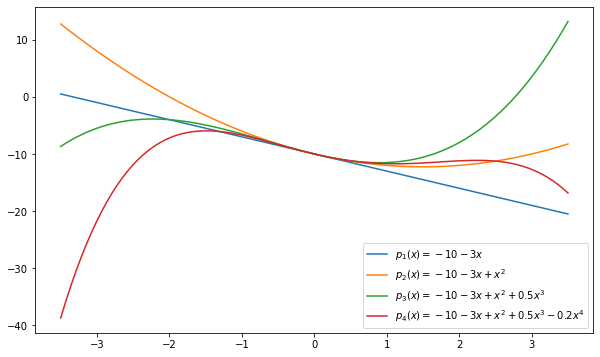

In [2]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-3.5,3.5,100)
y1 = -10-3*x
y2 = -10-3*x+x**2
y3 = -10-3*x+x**2+0.5*x**3
y4 = -10-3*x+x**2+0.5*x**3-0.2*x**4
fig = plt.figure(1, figsize=(10, 6))
plt.plot(x,y1, label="$p_1(x) = -10-3x$")
plt.plot(x,y2, label="$p_2(x) = -10-3x+x^2$")
plt.plot(x,y3, label="$p_3(x) = -10-3x+x^2+0.5x^3$")
plt.plot(x,y4, label="$p_4(x) = -10-3x+x^2+0.5x^3-0.2x^4$")
plt.legend()
plt.show()

Ainsi nous allons pouvoir formuler à partir d'un jeu de données $(X,y)$ des fonctions hypothèses de la forme suivante : 

- si $X$ n'est composé que d'une seule variable explicative, notée $X_1$ (régression univariée), la fonction hypothèse à base d'un polynôme de degré \(k\) s'écrit de la manière suivante :
$$
h(X) = \theta_0 + \theta_1 X_1 + \theta_2 X_1^2 + \ldots + \theta_k X_1^k + \dots = \theta_0 + \sum_{j=1}^k \theta_j X_1^j
$$
- si $X$ est composé de plusieurs variables explicatives (régression   multivariée), par exemple ici $X_1$ et $X_2$, la fonction hypothèse à base d'un polynôme de degré $k$ s'écrit de la manière suivante :
$$
h(X) = \theta_0 + \sum_{j=1}^k \left( \theta_{1,j} X_1^j + \theta_{2,j} X_2^j \right)
$$

En pratique, les calculs de minimisation du critère de moindres carrés par la méthode de gradient s'opèrent de la même manière que dans le cas de la régression linéaire univariée ou multivariée (qui correspond à $k=1$). La généralisation des formules vues dans le cas linéaire est sans difficulté. Elle n'est pas présentée ici et fait l'objet d'un exercice de TP.

Dans les implémentations qui suivent, nous ne développons donc pas ces formules de calcul mais nous utilisons les fonctions implémentées dans la bibliothèque `scikit-learn` dédiée au maching learning.


### Mise en oeuvre avec `scikit-learn`

Nous commençons par générer un jeu de données généré avec un polynome auquel est ajouté un ``bruit'' aléatoire.

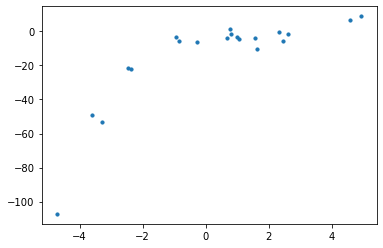

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
x = 2 - 3 * np.random.normal(0, 1, 20)
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)
plt.scatter(x,y, s=10) # s pour size/taille des points
plt.show()

Nous implémentons ci-dessous un calcul de régression linéaire sur le jeu de données précédent, en utilisant la bibliothèque `scikit-learn` (`sklearn`).

x.shape :  (20,)
x.shape :  (20, 1)


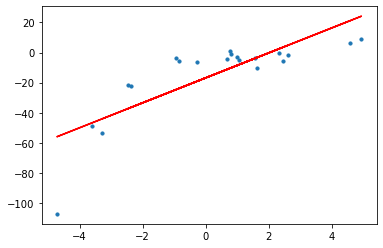

rmse = 15.908242501429998 , r2 = 0.6386750054827146


In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)
x = 2 - 3 * np.random.normal(0, 1, 20)
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)
print("x.shape : ",x.shape) # sert à comprendre la transformation à effectuer

# transformation des vecteurs 1D de format (n,) en une matrice 2D de n lignes et 1 colonne, de format (n,1)
x = x[:, np.newaxis]
y = y[:, np.newaxis]
print("x.shape : ",x.shape) # sert à comprendre la transformation effectuée

model = LinearRegression()
model.fit(x, y)
y_pred = model.predict(x)

plt.scatter(x, y, s=10)
plt.plot(x, y_pred, color='r')
plt.show()

rmse = np.sqrt(mean_squared_error(y,y_pred))
r2 = r2_score(y,y_pred)
print("rmse =", rmse, ", r2 =", r2)


Le programme se termine par le calcul de 2 indicateurs : 

- `rmse` - Root of Mean Squared Error - correspond à la distance entre les valeurs prédites, 
$\{h(x_i), 0 \leq i \leq n\}$ et les valeurs des données
$\{y_i, 0 \leq i \leq n\}$ ;
$$
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(h(x_i)-y_i)^2} 
$$
Cet indicateur mesure ainsi la proximité de la courbe de régression (de la fonction hypothèse) avec les données. 
 
- `r2` ou `r2\_score`, appelé *coefficient de détermination* va permettre d'évaluer la qualité de
la prédiction :
$$
1-\frac{\sum_{i=1}^n (h(x_i)-y_i)^2}{\sum_{i=1}^n (\overline{y}-y_i)^2}
$$
où $\overline{y} = \frac{1}{n}\sum_{i=1}^n y_i$ est un calcul de moyenne. La valeur numérique de `r2` est comprise entre 0 et 1. Si elle vaut 1, la régression est parfaite par rapport au jeu de données. Si elle vaut 0, la régression n'est pas du tout pertinente pour le jeu de données.

Nous allons maintenant définir une fonction hypothèse de régression à partir d'un polynome d'ordre $k$ :
$$
h(x) = \theta_0 + \sum_{j=1}^k \theta_j x^j
$$

Cette expression reste linéaire par rapport aux $\theta_j$, les coefficients à calculer.

Pour simplifier les calculs qui suivent (sans perte de généralité), nous recherchons un modèle/hypothèse univarié de regression polynomiale uniquement de de degré 3, à partir des données $(x_i, y_i)$ :
$$
h(x) = \theta_0 + \theta_1 x + \theta_2 x^2 + \theta_3 x^3
$$

**Calcul de régression basé sur `sckikit-learn`**

Nous commençons alors par déclarer le degré du modèle :

`poly = PolynomialFeatures(degree=3)`

Nous réécrivons le modèle précédent sous la forme **linéaire** suivante :
$$
h(t,u,v,w) = \theta_0 t + \theta_1 u + \theta_2 v + \theta_3 w
$$

avec $t=1, u=x, v=x^2, w=x^3$

Nous venons ainsi de transformer un modèle polynomial de degré 3, utilisant une variable explicative $(x)$ en un modèle linéaire (de degré 1) utilisant quatre variables explicatives $(t,u,v,w)$.

Cette transformation est effectuée dans `sckikit-learn` grâce à la fonction

`x_poly = poly.fit_transform(x)`

qui construit une matrice de données telle que la ligne i corresponde à
$(t_i, u_i, v_i, w_i)$, c'est à dire $(1, x_i, x_i^2, x_i^3)$.

Il ne reste plus qu'à appeler un calcul de régression linéaire sur ce nouvel espace de données, comme cela est décrit dans le script de calcul de régression linéaire présenté précédemment.


x =
 [[-4.7226796 ]
 [-3.60267397]
 [-3.29215704]
 [-2.48223722]
 [-2.36282052]
 [-0.93621395]
 [-0.85026525]
 [-0.28311318]
 [ 0.6684103 ]
 [ 0.76820449]
 [ 0.79952837]
 [ 0.99897702]
 [ 1.0607969 ]
 [ 1.56786929]
 [ 1.63497495]
 [ 2.30965656]
 [ 2.45407162]
 [ 2.61547479]
 [ 4.56228722]
 [ 4.93183364]]
Donner le degré de régression polynomiale souhaité : 
7
x_poly =
 [[ 1.00000000e+00 -4.72267960e+00  2.23037026e+01 -1.05333241e+02
   4.97455149e+02 -2.34932128e+03  1.10950917e+04 -5.23985631e+04]
 [ 1.00000000e+00 -3.60267397e+00  1.29792597e+01 -4.67600412e+01
   1.68461183e+02 -6.06910720e+02  2.18650145e+03 -7.87725188e+03]
 [ 1.00000000e+00 -3.29215704e+00  1.08382980e+01 -3.56813789e+01
   1.17468703e+02 -3.86725416e+02  1.27316080e+03 -4.19144529e+03]
 [ 1.00000000e+00 -2.48223722e+00  6.16150161e+00 -1.52943086e+01
   3.79641021e+01 -9.42359073e+01  2.33915877e+02 -5.80634695e+02]
 [ 1.00000000e+00 -2.36282052e+00  5.58292081e+00 -1.31914399e+01
   3.11690048e+01 -7.36467642e

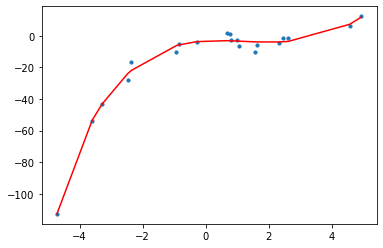

In [5]:
import operator

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
x = 2 - 3 * np.random.normal(0, 1, 20)
x.sort()
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)

# transformation des vecteurs 1D en matrice à 1 colonne
x = x[:, np.newaxis]
y = y[:, np.newaxis]
print("x =\n",x)

#version interactive du choix du polynome
print("Donner le degré de régression polynomiale souhaité : ")
ndegre=int(input())

polynomial_features= PolynomialFeatures(degree=ndegre)
x_poly = polynomial_features.fit_transform(x)
print("x_poly =\n",x_poly)

model = LinearRegression()
model.fit(x_poly, y)
y_poly_pred = model.predict(x_poly)

rmse = np.sqrt(mean_squared_error(y,y_poly_pred))
r2 = r2_score(y,y_poly_pred)
print("rmse =", rmse, ", r2 =", r2)

plt.scatter(x, y, s=10)
plt.plot(x, y_poly_pred, color='r')
plt.show()

Dans le script suivant, nous reprenons le même calcul en faisant varier le degré du polynôme de régression parmi les valeurs : $\{1, 2, 3, 20 \}$. 

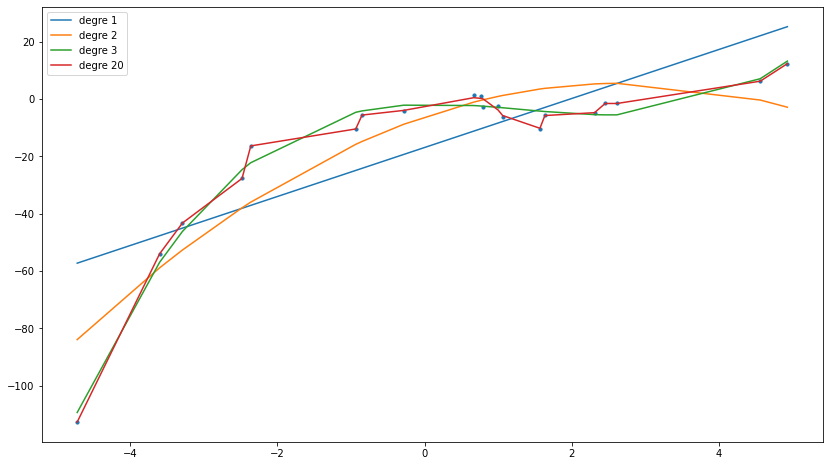

In [6]:
import operator

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
x = 2 - 3 * np.random.normal(0, 1, 20)
x.sort()
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)

# transformation des vecteurs 1D en matrice à 1 colonne
x = x[:, np.newaxis]
y = y[:, np.newaxis]

fig = plt.figure(1, figsize=(14, 8))

plt.scatter(x, y, s=10)

for ndegre in [1,2,3,20]:
    polynomial_features= PolynomialFeatures(degree=ndegre)
    x_poly = polynomial_features.fit_transform(x)

    model = LinearRegression()
    model.fit(x_poly, y)
    y_poly_pred = model.predict(x_poly)

    #rmse = np.sqrt(mean_squared_error(y,y_poly_pred))
    #r2 = r2_score(y,y_poly_pred)
    #print("rmse =", rmse, ", r2 =", r2)

    plt.plot(x, y_poly_pred, label="degre "+str(ndegre))

plt.legend()
plt.show()

Après avoir comparer les courbes polynomiales de régression sur une même figure, nous les traçons dans le script suivant, les unes après les autres, en affichant pour chaque courbe et donc pour chaque degré de polynôme, les indicateurs `rmse` et `r2`.

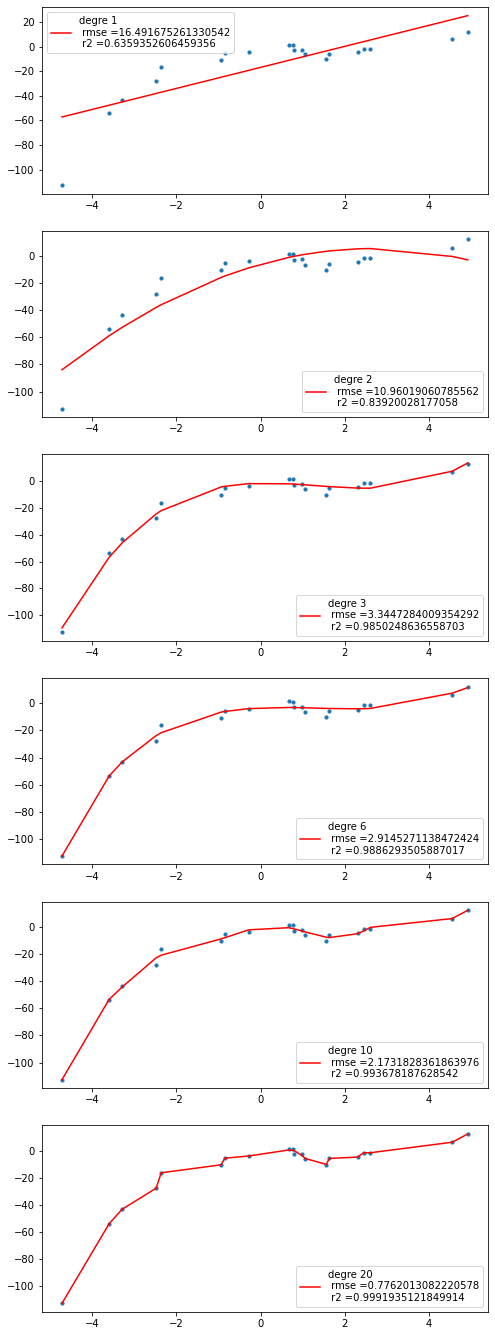

In [7]:
import operator

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
x = 2 - 3 * np.random.normal(0, 1, 20)
x.sort()
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 20)

# transformation des vecteurs 1D en matrice à 1 colonne
x = x[:, np.newaxis]
y = y[:, np.newaxis]

fig, g = plt.subplots(6, figsize=(8, 24))
ig = 0

for ndegre in [1,2,3,6,10,20]:
    g[ig].scatter(x,y,s=10)
    polynomial_features= PolynomialFeatures(degree=ndegre)
    x_poly = polynomial_features.fit_transform(x)
    
    model = LinearRegression()
    model.fit(x_poly, y)
    y_poly_pred = model.predict(x_poly)

    rmse = np.sqrt(mean_squared_error(y,y_poly_pred))
    r2 = r2_score(y,y_poly_pred)
    
    g[ig].plot(x, y_poly_pred, c='r', label="degre "+str(ndegre)+"\n rmse ="+str(rmse)+"\n r2 ="+str(r2))
    g[ig].legend()
    ig = ig+1

#plt.show()

La régression polynomiale de degré 20 fait apparaître des irrégularités qui correspondent au ``bruit'' qui est présent dans les données. On parle alors de phénomène de **sur-apprentissage (over-fitting)**. La courbe est très proche des données mais si on ajoutait des données supplémentaires, la courbe du polynôme de degré 20 pourrait être assez différente. Ses oscillations sont instables par rapport à l'ajout de points.

A l'opposé, la régression de degré 1 passe assez loin des données car la complexité du modèle (hypothèse) est trop faible. On parle alors de **sous-apprentissage (under-fitting)**. L'ajout d'une donnée va très peu modifié l'allure de la courbe de régression qui est stable par rapport à l'ajout de points.

Ces deux situations de sous-apprentissage et de sur-apprentissage ne sont pas spécifiques au problème de régresssion polynomiale mais peuvent se rencontrer dans de nombreux modèles/hypothèses qui sont paramètrables.

Le phénomène de sur-apprentissage est un problème difficile en science des données, puisqu'il faudrait savoir identifier ou mesurer le bruit présent dans les données. La question est donc de savoir choisir une *complexité* de modèle pertinente, ici le degré ``optimal'' de régression polynomiale. La notion de **compromis biais-variance** vise à apporter des méthodes d'analyse pour identifier ce degré optimal ou plus généralement le réglage de la complexité dans des modèles/hypothèses.

### Le compromis biais-variance

**Le biais** correspond à l'écart entre les données et le modèle. Si sa valeur est élevée, cela signifie que l'on est dans la situation de sous-apprentissage. les valeurs de `rmse` ou de `r2` permettent de mesurer le biais.

**La variance** correspond à une mesure du phénomène de sur-apprentissage dgénéré parl'usage d'un modèle *trop complexe*, c'est à dire trop sensible à des petites modifications apportées sur les données.

On illustre ces valeurs du biais et de la variance sur la figure suivante :

![biais-variance](tds-regpol4.png)

Nous pouvons observer sur ces figures que le biais va décroître avec le degré du polynôme choisi alors que la variance va croître.
Le *compromis* consiste donc à trouver une valeur *optimale* du degré pour lequel à la fois le biais et la variance ne sont pas trop grands, comme illustré sur la figure suivante où la courbe appelée **erreur totale** est une somme du biais et de la variance. Elle est parfois qualifiée d'**erreur de prédiction** [3] pour bien la distinguer des calculs d'erreurs de type `rmse`.


![optimal](tds-regpol5.png)


**Définition mathématique**

Soit un jeu de données $\{(x_i, y_i); 1 \leq i \leq n\}$, où $(x_i)$ sont les données d'entrée du modèle (chaque $x_i$ est,  soit une valeur simple dans un problème univarié, soit un vecteur de plusieurs valeurs dans un problème multivarié) et $(y_i)$ sont les données cibles. On note $h(x)$, la fonction hypothèse.

Comme dans la construction effectuée en début de chapitre, nous supposons que les données sont *bruitées* et le calcul de régression consiste alors à rechercher une fonction que l'on note $f(x)$ qui lisse ce bruit et que l'on définit à partir de l'expression : 
$$
y_i  = f(x_i) + \epsilon_i
$$ 
où
$\epsilon_i$ est un bruit dont la moyenne $\mu(\epsilon)$ est nulle et l'écart type est notée $\sigma^2$.

**Rappels** : 

**Définitions de la moyenne et de la variance d'une suite de données $z=(z_i, 1 \leq i \leq n)$**


- Calcul de la moyenne
$$
\mu(z) = \frac{1}{n} \sum_{i=1}^{n} z_i
$$
- La variance notée est la moyenne des carrés des écarts à la moyenne
$$
V(z) = \frac{1}{n}\sum_{i=1}^{n}(z_i - \mu(z))^2
$$
On peut montrer que
$$
V(z) = \left( \frac{1}{n}\sum_{i=1}^n z_i^2 \right) - \mu(z)^2 = \mu(z^2) - \mu(z)^2
$$
où on note $z^2=(z^2_i, 1 \leq i \leq n)$
- L'écart-type est la racine carrée de la variance
$$
\sigma = \sqrt{V(z)}
$$ 
Il permet de mesurer la dispersion des valeurs $z_i$ autour de la moyenne $\mu(z)$.



A partir du jeu de données $\{(x_i, y_i); 1 \leq i \leq n\}$, nous appelons échantillons d'apprentissage un ensemble $S$ de $m$ échantillons correspondant à des extractions des données initiales dont les tailles sont inférieures à $n$. 
Pour chaque échantillon de données, nous notons $x^p$, l'échantillon $p$ des données d'entrée (attention $p$ est un indice supérieur et non une élévation à la puissance). 

Nous effectuons alors un calcul de régression à partir de chaque échantillon pour trouver les coefficients des fonctions hypothèses associées à l'échantillon. La fonction hypothèse associée à l'échantillon $x^p$ est notée :
$$
h_{x^p}(x))
$$ 

Pour une valeur donnée de $x$, chaque fonction hypothèse donne une valeur différentes en $x$ car chacune est associé à un échantillon différents qui a servi à mener le calcul de régression qui permet de calculer les paramètres caractéristiques de la fonction hypothèse.


On définit alors la fonction $G(x)$ qui calcule la moyenne des valeurs renvoyées par toutes les fonctions hypothèses associées à un enchantillonage $S$ :
$$
G(x) = \frac{1}{m}\sum_{x^p \in S} h_{x^p}(x)
$$
où $m$ est le nombre d'échantillons $x_p$ dans $S$.

Nous appelons **espérance de $h$ par rapport à l'échantillonage $S$** sur les données $X = \{x_i, 1 \leq i \leq n\}$, la moyenne des valeurs que prend la fonction $G$ sur tous les $x_i$ :
$$
E_S[h(X)] = \frac{1}{n}\sum_{i=1}^{n} G(x_i)
$$

Nous pouvons maintenant définir de manière plus formelle les deux composantes du compromis biais-variance, relativement à un échantillonage $S$ :

- le biais se calcule par
$$
B(h(X))= E_S[(h-f)(X)]
$$
- la variance se calcule par
$$
Var(h(X))=E_S[h^2(X)]-(E_S[h(X)])^2
$$



On définit ensuite l'**erreur de prédiction** par
$$
Err(h(X)) = B^2(h(X)) + Var(h(X)) + \sigma^2
$$

où $\sigma^2$ est l'écart-type sur les données bruitées.
 
 
La fonction $f(x)$ n'étant pas une fonction connue, nous ne pouvons pas calculer directement le biais qui mesure l'écart entre l'hypothèse et les données *lissées* par $f(x)$.
Nous verrons en TP comment il est possible de faire une estimation simple mais fiable du biais.

Le calcul de la variance n'utilisant pas $f(x)$, nous pouvons par contre l'évaluer, à condition de mettre en place un échantillonnage $S$. Elle mesure la dispersion des fonctions hypothèses liées à un échantillon à la moyenne de ces fonctions hypothèses pour tous les échantillons. 
En cas de sur-apprentissage, cette dispersion peut être grande comme cela a été expliqué dans les exemples précédents. Nous verrons en TP comment il est possible de faire une estimation simple de la variance.

Le calcul du compromis biais-variance reste assez technique si nous respectons sa définition théorique. Il nécessite l'extraction d'un échantillonage. Nous verrons en TP comment il est possible de l'évaluer simplement pour finalement obtenir une information fiable qui répond à nos attentes, à savoir estimer une *bonne* valeur de la complexité à retenir pour construire le modèle, c'est à dire la fonction hypothèse. Cette complexité correspond ici, au choix du degré du polynôme dans une régression polynomiale, en fonction des données du problème.


**Référence sur le compromis biais-variance**
1. [Dilemme biais-variance : article de Wikipedia](https://fr.wikipedia.org/wiki/Dilemme_biais-variance)
2. Scott Fortmann-Roe. "Understanding the Bias-Variance Tradeoff", [blog en ligne](http://scott.fortmann-roe.com/docs/BiasVariance.html), 2012
3. T. Hasyie, R. Tibshirani, J. Friedman. "The Elements of Statistical Learning", Springer, 2017 (2nd edition)
4. G. Gigerenzer, H. Brighton (2009) "Homo Heuristicus: Why biased Minds make Better Inferences", Topics in Cognitive Science 1, 107-143. Accessible en ligne [ici](https://pure.mpg.de/rest/items/item_2099728/component/file_2563980/content)


### Techniques de régularisation
Dans les méthodes de régression, la fonction de coût $J(\theta)$ sert à ajuster les paramètres du modèle / fonction hypothèse en fonction des données.

Avec la régression polynomiale, des problèmes de sur-apprentissage peuvent apparaître et alors la minimisation de cette fonction de coût produit des modèles *instables* et donc très sensibles à des petites modifications sur les données. 

Pour pallier à ce problème, le principe de la régularisation est de contraindre l'espace de recherche des paramètres 
$\theta$ en modifiant la fonction coût : $J(\theta)$. Il s'agit donc de *pénaliser* certaines valeurs que pourrait prendre $\theta$ en empêchant que celles-ci conduisent au minimum de la fonction de coût. On parle alors de
*rétressissement* de l'espace de recherche d'où le terme *shrinkage* en anglais.

Pratiquement, on va donc modifier  la focntion coût en  ajoutant une *fonction de pénalité* $P(\lambda,\theta)$ qui dépend de $\theta$ et d'un paramètre $\lambda$ que l'on va ajuster afin produire l'effet souhaité de régularisation :

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+P(\lambda,\theta)
$$

où $\{(x_i, y_i); 1 \leq i \leq m\}$ sont les données et ${(\theta_j; 0 \leq j \leq n}$ les paramètres de la fonction hypothèse à ajuster.

Nous présentons dans la suite, les techniques de régularisation les plus fréquentes.

**Régularisation de Ridge**

La fonction de pénalisation se base sur l'utilisation de la norme $L_2$ du vecteur $\theta$. Appelée aussi norme euclidienne, elle correspond aux métriques et notamment aux distances usuelles en géométrie. La fonction de pénalisation s'écrit :

$$
P_r(\lambda, \theta) = \lambda \sum_{j=0}^{n}\theta_j^2
$$

et donc la fonction coût "pénalisée" s'écrit

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+\lambda \sum_{j=0}^{n}\theta_j^2
$$

Dans cette expression, des grandes valeurs de $\theta_j$ vont *pénaliser* le calcul de la recherche du minimum. 
Elles seront ainsi exclues des solutions potentielles.

**Régression lasso**

La fonction de pénalisation lasso (Least Absolute Shrinkage and Selection Operator) est identique mais se base sur la norme $L_1$ :

$$
P_l(\lambda, \theta) = \lambda \sum_{j=0}^{n} \lvert \theta_j \rvert
$$

**Régression ElasticNet**

La fonction de pénalisation est une composition des deux précédentes, en ajoutant un nouveau paramètre $\alpha$ mesurant l'importance donnée à l'une des deux fonctions de pénalisation précédente par rapport à l'autre.

$$
P_e(\lambda, \theta) = \lambda \sum_{j=0}^{n} \left( \alpha \theta_j^2 + (1-\alpha) \lvert \theta_j \rvert \right)
$$

L'impact des techniques de régularisation avec ces fonctions de pénalisation sera étudié dans les TP.


**Références sur les techniques de régularisation**
1. E. Biernat et M. Lutz (2015) "Data science : fondamentaux et études de cas: Machine learning avec Python et R", Editions Eyrolles
2. [Blog de Xavier Dupré, Régression Ridge, Lasso et nouvel estimateur](http://www.xavierdupre.fr/app/papierstat/helpsphinx/notebooks/2020-02-07_sklapi.html)